# Name: Dhanashree sainis
# Class: B-B2
# Roll no:28
# ML lab 8

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report,ConfusionMatrixDisplay,precision_score,recall_score,f1_score)
import warnings
warnings.filterwarnings('ignore')


In [ ]:
df=pd.read_csv("ai4i2020.csv")

In [ ]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [ ]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [ ]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
df.shape

(10000, 14)

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [ ]:
df["Type"].unique()

array(['M', 'L', 'H'], dtype=object)

In [ ]:
df["Machine failure"].value_counts()

,count
Machine failure,
0,9661
1,339


In [ ]:
df["Machine failure"].value_counts(normalize=True)*100

,proportion
Machine failure,
0,96.61
1,3.39


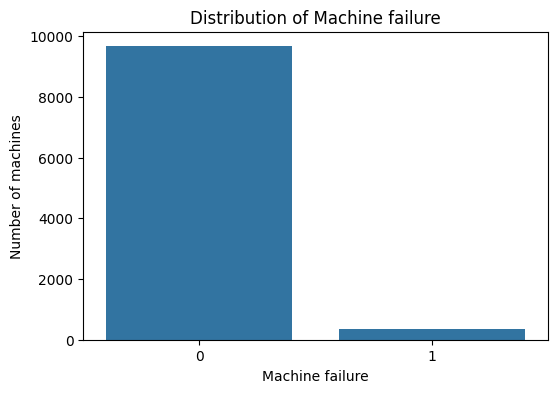

In [ ]:

plt.figure(figsize=(6,4))
sns.countplot(x="Machine failure",data=df)
plt.title("Distribution of Machine failure")
plt.xlabel("Machine failure")
plt.ylabel("Number of machines")
plt.show()

In [ ]:
numerical_features=["Air temperature [K]"	,"Process temperature [K]"	,"Rotational speed [rpm]"	,"Torque [Nm]"	,"Tool wear [min]"]

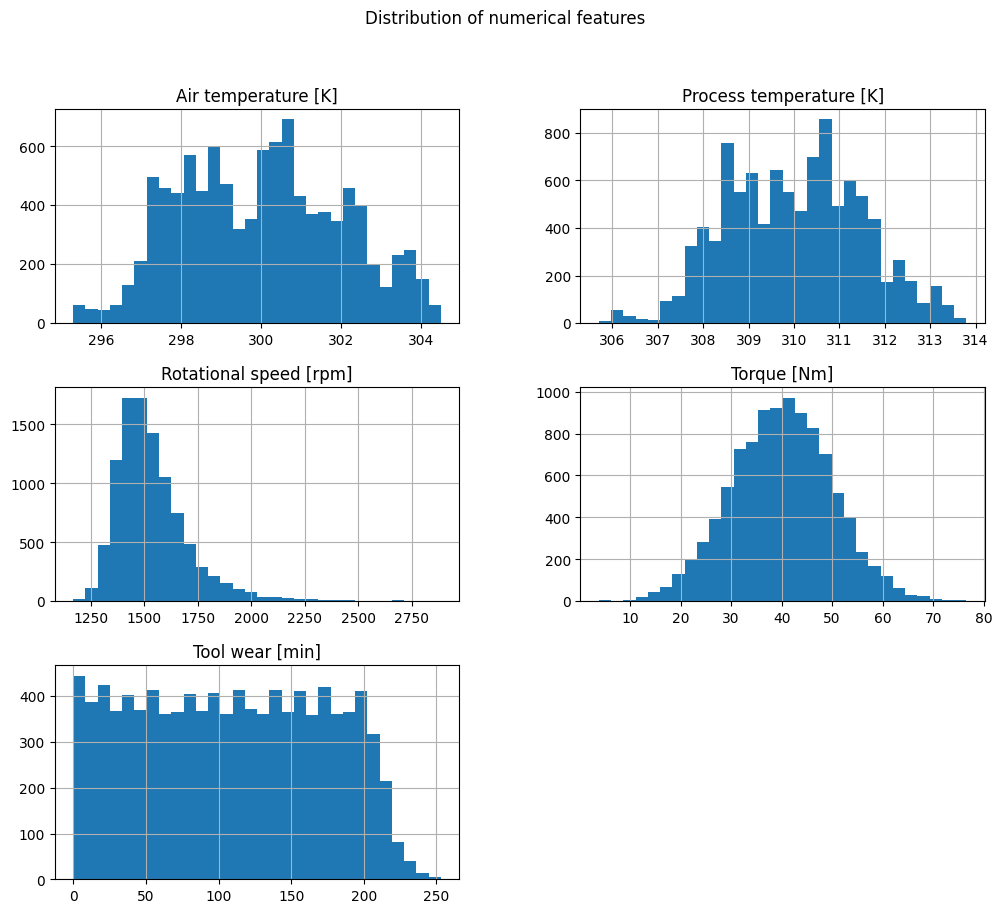

In [ ]:
df[numerical_features].hist(figsize=(12,10),bins=30)
plt.suptitle("Distribution of numerical features")
plt.show()


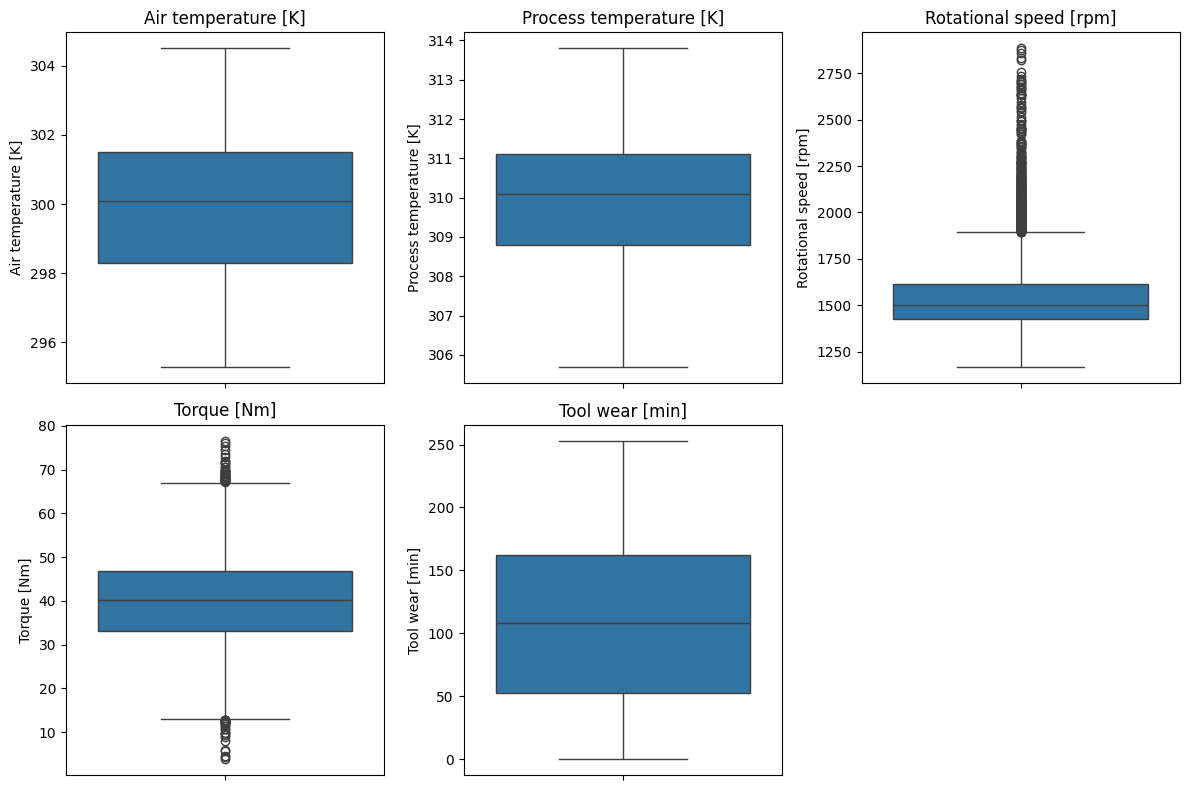

In [ ]:
plt.figure(figsize=(12,8))
for i,column in  enumerate(numerical_features,1):
  plt.subplot(2,3,i)
  sns.boxplot(df[column])
  plt.title(column)
plt.tight_layout()
plt.show()

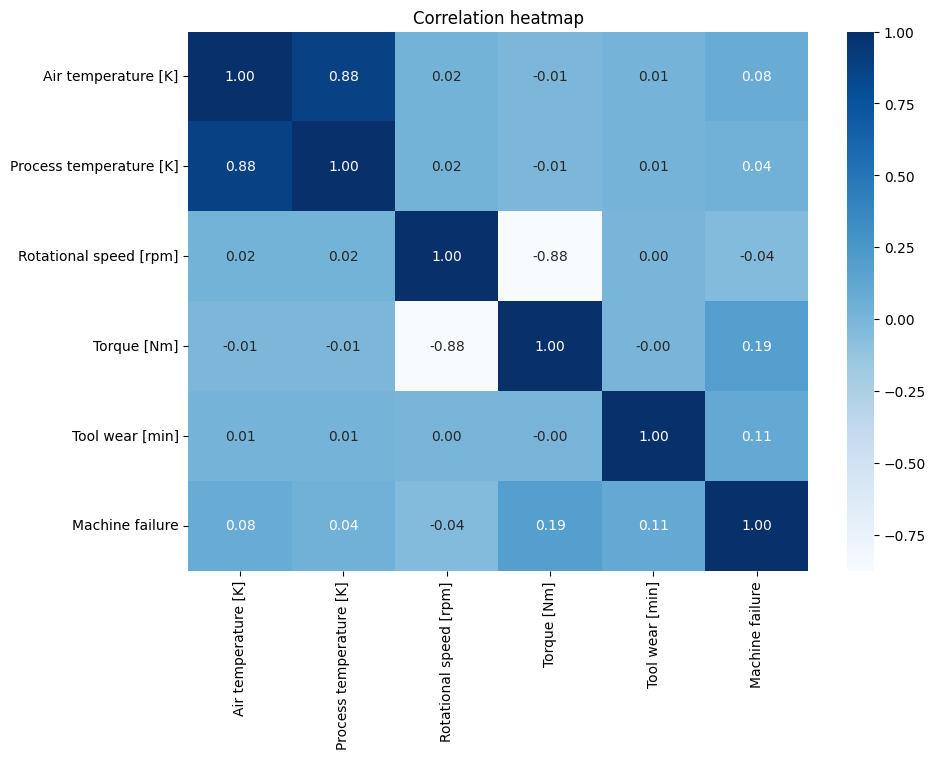

In [ ]:
plt.figure(figsize=(10,7))
correlation=df[numerical_features+["Machine failure"]].corr()
sns.heatmap(correlation,annot=True,cmap="Blues",fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

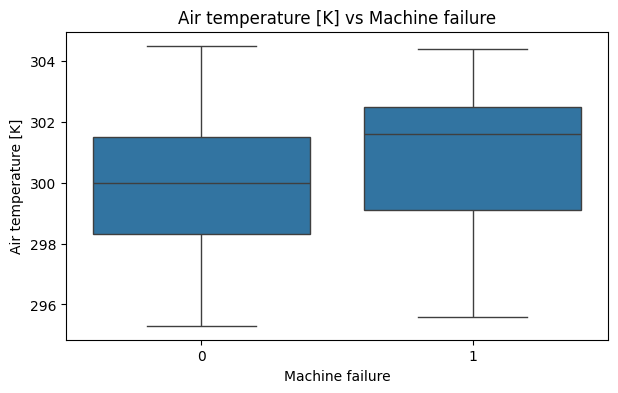

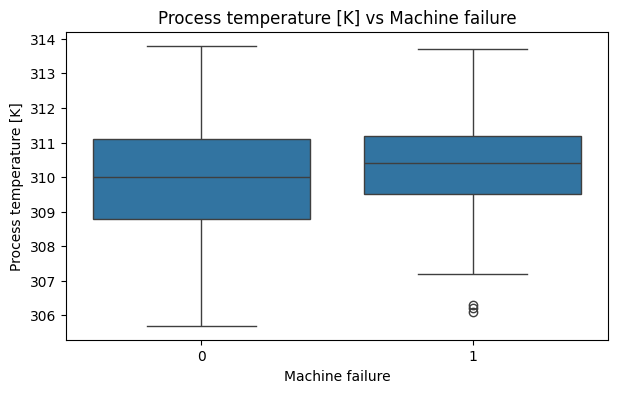

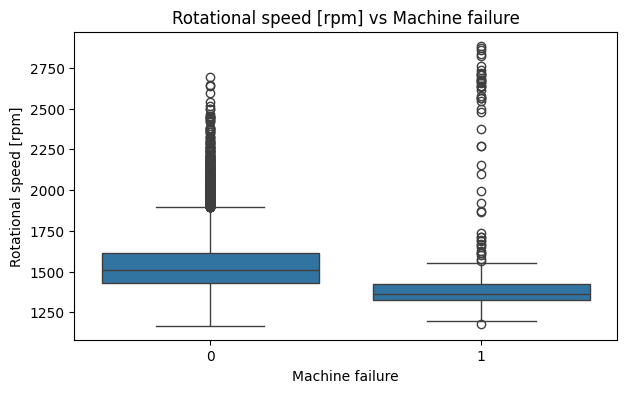

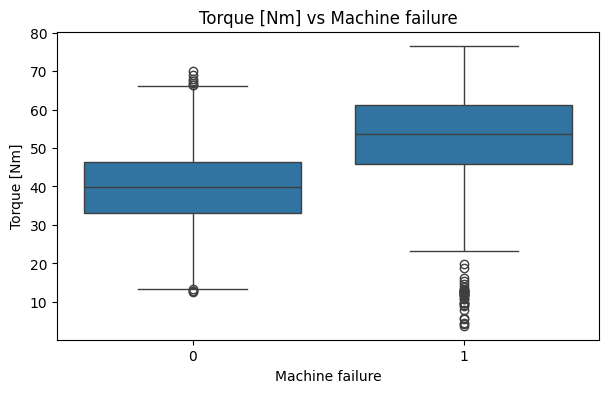

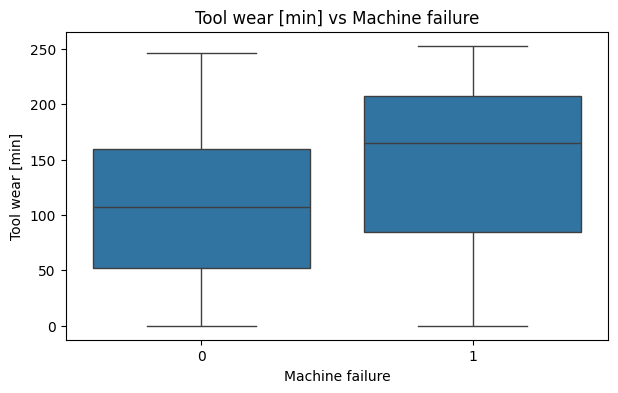

In [ ]:
for column in numerical_features:
  plt.figure(figsize=(7,4))
  sns.boxplot(x="Machine failure",y=column,data=df)
  plt.title(f"{column} vs Machine failure")
  plt.show()


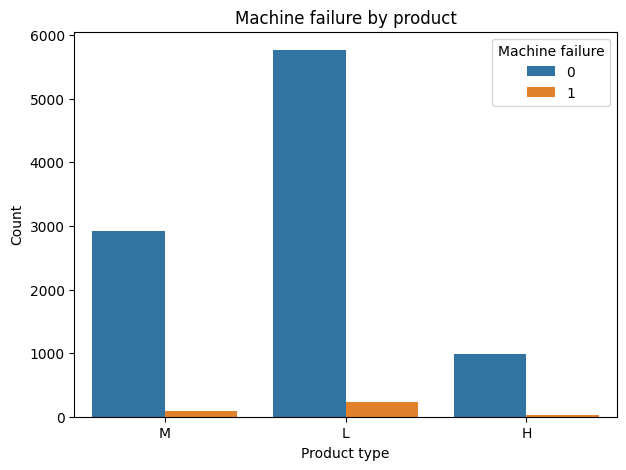

In [ ]:
plt.figure(figsize=(7,5))
sns.countplot(x="Type",hue="Machine failure",data=df)
plt.title("Machine failure by product")
plt.xlabel("Product type")
plt.ylabel("Count")
plt.show()

In [ ]:
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]
y = df["Machine failure"]

In [ ]:
print("Input shape:",X.shape)
print("Output shape:",y.shape)

Input shape: (10000, 6)
Output shape: (10000,)


In [ ]:
categorical_features=["Type"]
numerical_features=["Air temperature [K]"	,"Process temperature [K]"	,"Rotational speed [rpm]"	,"Torque [Nm]"	,"Tool wear [min]"]


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training samples:",X_train.shape[0])
print("Testing samples:",X_test.shape[0])

Training samples: 8000
Testing samples: 2000


In [ ]:
preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features)
    ]
)


In [ ]:
linear_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="linear"))
    ]
)

linear_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [ ]:
y_pred_linear=linear_svm.predict(X_test)

In [ ]:
accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(y_test, y_pred_linear, zero_division=0)
recall_linear = recall_score(y_test, y_pred_linear, zero_division=0)
f1_linear = f1_score(y_test, y_pred_linear, zero_division=0)

print("Accuracy:", accuracy_linear)
print("Precision:", precision_linear)
print("Recall:", recall_linear)
print("F1 score:", f1_linear)

Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 score: 0.0


In [ ]:
print(classification_report(
    y_test,y_pred_linear,target_names=["No failure","Failure"],zero_division=0)
    )

              precision    recall  f1-score   support

  No failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



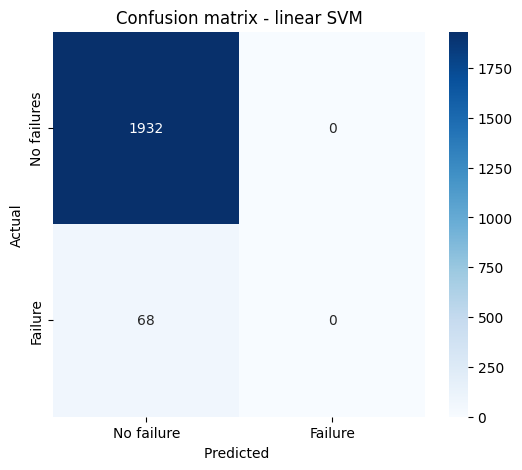

In [ ]:
cm_linear=confusion_matrix(y_test,y_pred_linear)
plt.figure(figsize=(6,5))
sns.heatmap(cm_linear,annot=True,fmt="d",cmap="Blues",xticklabels=["No failure","Failure"],yticklabels=["No failures","Failure"])

plt.xlabel("Predicted ")
plt.ylabel("Actual")
plt.title("Confusion matrix - linear SVM")
plt.show()

In [ ]:
rbf_svm=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",SVC(kernel="rbf"))
    ]
)
rbf_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [ ]:
y_pred_rbf=rbf_svm.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf, zero_division=0)
recall_rbf = recall_score(y_test, y_pred_rbf, zero_division=0)
f1_rbf = f1_score(y_test, y_pred_rbf)

print("RBF SVM results")
print("Accuracy:", accuracy_rbf)
print("Precision:", precision_rbf)
print("Recall:", recall_rbf)
print("F1 score:", f1_rbf)

RBF SVM results
Accuracy: 0.972
Precision: 0.875
Recall: 0.20588235294117646
F1 score: 0.3333333333333333


In [ ]:
print(classification_report(y_test,y_pred_rbf,target_names=["No failure","Failure"],zero_division=0))

              precision    recall  f1-score   support

  No failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



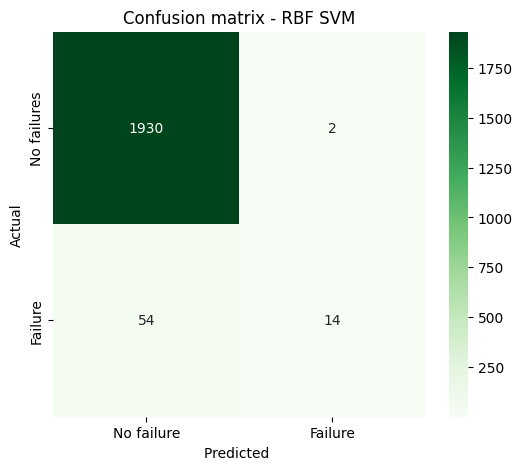

In [ ]:
cm_rbf=confusion_matrix(y_test,y_pred_rbf)
plt.figure(figsize=(6,5))
sns.heatmap(cm_rbf,annot=True,fmt="d",cmap="Greens",xticklabels=["No failure","Failure"],yticklabels=["No failures","Failure"])

plt.xlabel("Predicted ")
plt.ylabel("Actual")
plt.title("Confusion matrix - RBF SVM")
plt.show()

In [ ]:
comparision = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM"],
    "Accuracy": [accuracy_linear, accuracy_rbf],
    "Precision": [precision_linear, precision_rbf],
    "Recall": [recall_linear, recall_rbf],
    "F1 score": [f1_linear, f1_rbf]
})
comparision

,Model,Accuracy,Precision,Recall,F1 score
0,Linear SVM,0.966,0.000,0.000000,0.000000
1,RBF SVM,0.972,0.875,0.205882,0.333333


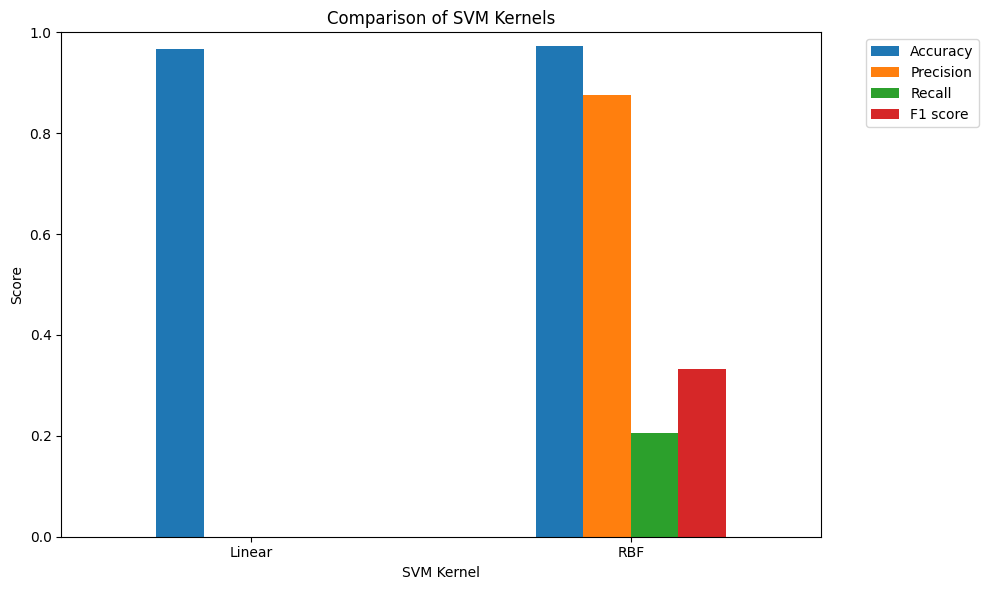

In [ ]:
comparison = pd.DataFrame({
    "Kernel": ["Linear", "RBF"],
    "Accuracy": [accuracy_linear, accuracy_rbf],
    "Precision": [precision_linear, precision_rbf],
    "Recall": [recall_linear, recall_rbf],
    "F1 score": [f1_linear, f1_rbf]
})

comparison_plot = comparison.set_index("Kernel")
comparison_plot.plot(kind="bar", figsize=(10,6))

plt.title("Comparison of SVM Kernels")
plt.xlabel("SVM Kernel")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05,1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.pipeline import Pipeline
pipeline=Pipeline(
    steps=[("preprocessor",preprocessor),("classifier",SVC(kernel="rbf"))]
)

In [ ]:
param_grid = [
    {"classifier__kernel": ["linear"], "classifier__C": [0.1, 1, 10, 100]},
    {"classifier__kernel": ["rbf"], "classifier__gamma": ["scale", 1, 0.1, 0.01, 0.001], "classifier__C": [0.1, 1, 10, 100]}
]

In [ ]:
grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best parameters found:", grid_search.best_params_)
print("Best cross-validation F1 score:", grid_search.best_score_)

Best parameters found: {'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
Best cross-validation F1 score: 0.7080372186703207


In [ ]:
best_model=grid.search.best_estimator_
y_pred_best=best_model.predict(X_test)

In [ ]:
accuarcy_tunnedaccuracy_score(y_test,y_pred_best)
precision_tunned=precision_score(y_test,y_pred_best,zero_division=0)
recall_tunned=recall_score(y_test,y_pred_best,zero_division=0)
f1_tunned=f1_score(y_test,y_pred_best,zero_division=0)
print("Accuracy:",accuarcy_tunned)
print("Precision:",precision_tunned)
print("Recall:",recall_tunned)
print("F1 score:",f1_tunned)

In [ ]:
final_comparision=pd.DataFrame({
    "Model":["Linear SVM","RBF SVM","Tunned SVM"],
    "Accuracy":[accuracy_linear,accuracy_rbf,accuracy_tunned],
    "Precision":[precision_linear,precision_rbf,precision_tunned],
    "Recall":[recall_linear,recall_rbf,recall_tunned],
    "F1 score":[f1_linear,f1_rbf,f1_tunned]
})
final_comparision

In [ ]:

final_comparison.set.index("Model").plot(kind="bar", figsize=(11,6))

plt.title("Performance Comparison of SVM Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05,1), loc="upper left")
plt.tight_layout()
plt.show()